In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
student_data=pd.read_csv('student_performance_dataset.csv')
print(student_data.head())

  Student_ID  Gender  Study_Hours_per_Week  Attendance_Rate  Past_Exam_Scores  \
0       S147    Male                    31        68.267841                86   
1       S136    Male                    16        78.222927                73   
2       S209  Female                    21        87.525096                74   
3       S458  Female                    27        92.076483                99   
4       S078  Female                    37        98.655517                63   

  Parental_Education_Level Internet_Access_at_Home Extracurricular_Activities  \
0              High School                     Yes                        Yes   
1                      PhD                      No                         No   
2                      PhD                     Yes                         No   
3                Bachelors                      No                         No   
4                  Masters                      No                        Yes   

   Final_Exam_Score Pass_F

In [24]:
x=student_data[["Past_Exam_Scores","Study_Hours_per_Week","Attendance_Rate"]].to_numpy()
y=student_data["Final_Exam_Score"].to_numpy()

In [30]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("X shape:", x.shape)
print("y shape:", y.shape)

print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)

X shape: (708, 3)
y shape: (708,)
X_train shape: (566, 3)
X_test shape: (142, 3)


In [32]:
def compute_prediction(x,w,b):
    return np.dot(x,w)+b
w = np.zeros(3)
b = 0

predictions = compute_prediction(x_train, w, b)

print(predictions.shape)
print(predictions[:5])

(566,)
[0. 0. 0. 0. 0.]


In [33]:
def compute_cost(x,y,w,b):
    m=x.shape[0]
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    cost=np.sum(error**2)/(2*m)
    return cost

In [34]:
print("Mean:", np.mean(x_train, axis=0))
print("Standard deviation:", np.std(x_train, axis=0))

Mean: [77.71908127 26.52650177 77.82440943]
Standard deviation: [14.50955174  8.85085515 13.87156963]


In [35]:
# feature normalization
mean=np.mean(x_train, axis=0)
std=np.std(x_train,axis=0)
x_train_norm=(x_train-mean)/std
x_test_norm=(x_test-mean)/std
print("normalized mean:", np.mean(x_train_norm,axis=0))
print('normalized std:',np.std(x_train_norm,axis=0))

normalized mean: [-1.30392360e-16 -4.94304244e-17  2.08922004e-15]
normalized std: [1. 1. 1.]


In [36]:
def compute_gradient(x,y,w,b):
    y_pred=compute_prediction(x,w,b)
    error=y_pred-y
    m=x.shape[0]
    dj_dw=(x.T @ error)/m
    dj_db=np.sum(error)/(m)
    return dj_dw,dj_db
w = np.zeros(3)
b = 0

dj_dw, dj_db = compute_gradient(
    x_train_norm, y_train, w, b
)

print("dj_dw:", dj_dw)
print("dj_dw shape:", dj_dw.shape)
print("dj_db:", dj_db)

dj_dw: [-3.32625532 -2.29735755 -3.06475887]
dj_dw shape: (3,)
dj_db: -58.84628975265018


In [37]:
def gradient_descent(x,y,w,b,alpha,iterations):
    cost_history=[]
    for i in range(iterations):
        dj_dw,dj_db=compute_gradient(x,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        cost=compute_cost(x,y,w,b)
        cost_history.append(cost)
    return w,b,cost_history
w = np.zeros(3)
b = 0

w_final, b_final,cost_history = gradient_descent(
    x_train_norm,
    y_train,
    w,
    b,
    alpha=0.01,
    iterations=1000
)

print("Final weights:", w_final)
print("Final bias:", b_final)

Final weights: [3.41364795 2.39323714 3.11298522]
Final bias: 58.84374928491606


In [38]:
train_cost = compute_cost(
    x_train_norm,
    y_train,
    w_final,
    b_final
)

print("Training cost:", train_cost)

Training cost: 9.537252396550855


In [39]:
test_cost= compute_cost(x_test_norm,
y_test,w_final,b_final)
print("Test cost:", test_cost)

Test cost: 7.19042549995411


In [40]:
y_test_pred=compute_prediction(x_test_norm,w_final,b_final)
y_train_pred=compute_prediction(x_train_norm, w_final, b_final)




In [41]:
mae=mean_absolute_error(y_test_pred,y_test)
mse=mean_squared_error(y_test_pred,y_test)
r2=r2_score(y_test,y_test_pred)
print("MSE: ",mse)
print("MAE: ",mae)
print("R2: ",r2)

MSE:  14.38085099990822
MAE:  3.0620733635062543
R2:  0.6619847838767686


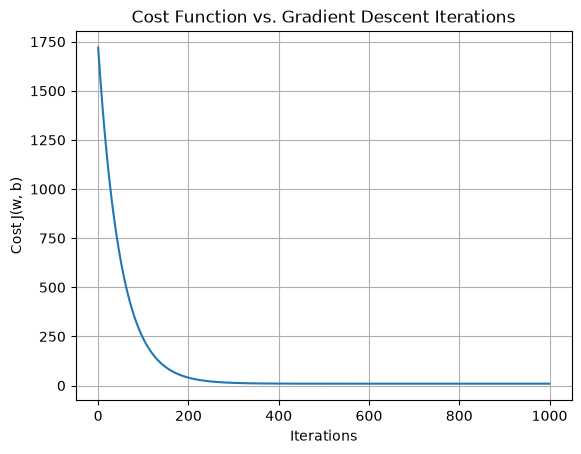

In [48]:
plt.plot(cost_history)
plt.title("Cost Function vs. Gradient Descent Iterations")
plt.xlabel("Iterations")
plt.ylabel("Cost J(w, b)")
plt.grid(True)
plt.show()

In [46]:
# convert normalized weights and bias back to original scale
w_original=w_final/std
b_original=b_final-np.sum(mean*w_original)
print("Original weights:", w_original)
print("Original bias:", b_original)

Original weights: [0.23526902 0.27039615 0.22441478]
Original bias: 15.921246095672885


scitkit-learn comparision

In [49]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.24,0.27,0.22]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,15.92
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[345.44,329.82,210.47]"


In [50]:
print("weights(coefficients): ", model.coef_)
print("bias(intercept):", model.intercept_)

weights(coefficients):  [0.23528226 0.27041319 0.22442624]
bias(intercept): 15.92141373519361


In [52]:
y_pred = model.predict(x_test)

In [53]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 3.062121956898773
MSE: 14.382452806519584
RMSE: 3.7924204416862306
R2: 0.6619471341571567
